# Cardiovascular Disease Dataset — Regression Track
## Last 5 Regression Algorithms (6–10) + EDA & Preprocessing

This notebook implements the **remaining five regression algorithms** required by the capstone:
6. Decision Tree Regressor
7. Random Forest Regressor
8. Gradient Boosting Regressor
9. Support Vector Regressor (SVR)
10. K-Nearest Neighbors Regressor (KNN)

It also includes a dedicated **EDA and preprocessing stage** before model training:
- Missing-value inspection
- Data-type and descriptive-statistics checks
- Target and feature distribution plots
- Box plots for numerical features
- IQR-based statistical outlier detection
- Domain-range validation and outlier treatment
- Scatter plots between important numerical features and the target
- Correlation heatmap
- Duplicate detection
- BMI feature engineering
- Categorical/binary value validation
- Train/test split and leakage-safe preprocessing pipelines

### Regression target
**`ap_hi` — systolic blood pressure**

### Runtime note
RBF-kernel SVR is trained and tuned on a fixed, reproducible **5,000-row training subsample** because
kernel SVR becomes expensive on large datasets. It is still evaluated on the full held-out test set.
Random Forest tuning is also kept modest so the notebook remains practical on a laptop.


In [1]:
# Imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load the Dataset

In [2]:
DATA_PATH = "HeartFailureDataset.csv"   # place the CSV in the same folder as this notebook

df = pd.read_csv(DATA_PATH)

print(f"Original shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())


Original shape: 70,000 rows x 13 columns


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62,110,80,1,1,0,0,1,0
1,1,20228,1,156,85,140,90,3,1,0,0,1,1
2,2,18857,1,165,64,130,70,3,1,0,0,0,1
3,3,17623,2,169,82,150,100,1,1,0,0,1,1
4,4,17474,1,156,56,100,60,1,1,0,0,0,0


## 2. Reproduce the Regression Preprocessing

To make the comparison with the first five algorithms fair, this notebook reproduces the same
preprocessing decisions used for algorithms 1–5:

- Remove exact duplicate rows and duplicate patient IDs (checked again after `id` is dropped, since
  two different IDs can still be identical on every other column)
- Drop `id`
- Convert `age` from days to years
- Engineer `bmi`
- Validate categorical/binary values are within their expected coded ranges
- Validate physical measurements against plausible clinical ranges (outlier detection + treatment)
- Require `ap_hi > ap_lo`
- Use `ap_hi` as the regression target
- Use an 80:20 split with temporary target bins for stratification
- Fit encoding/scaling only through pipelines (train-only fitting, no leakage into the test set)


In [3]:
clean = df.copy()

print("Initial missing values:")
display(clean.isna().sum().to_frame("missing_values").T)

# Remove duplicate observations
before_duplicates = len(clean)
clean = clean.drop_duplicates()
print(f"Exact duplicate rows removed: {before_duplicates - len(clean):,}")

# Remove duplicate patient IDs
before_id_duplicates = len(clean)
clean = clean.drop_duplicates(subset="id", keep="first")
print(f"Duplicate patient IDs removed: {before_id_duplicates - len(clean):,}")

# Remove identifier
clean = clean.drop(columns=["id"])

# Age: days -> years
clean["age_years"] = clean["age"] / 365.25
clean = clean.drop(columns=["age"])

# Feature engineering: BMI
height_m = clean["height"] / 100
clean["bmi"] = clean["weight"] / (height_m ** 2)

print(f"Shape after basic cleaning/feature engineering: {clean.shape[0]:,} rows x {clean.shape[1]} columns")
display(clean.head())


Initial missing values:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
missing_values,0,0,0,0,0,0,0,0,0,0,0,0,0


Exact duplicate rows removed: 0
Duplicate patient IDs removed: 0
Shape after basic cleaning/feature engineering: 70,000 rows x 13 columns


,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi
0,2,168,62,110,80,1,1,0,0,1,0,50.3573,21.9671
1,1,156,85,140,90,3,1,0,0,1,1,55.3812,34.9277
2,1,165,64,130,70,3,1,0,0,0,1,51.6277,23.5078
3,2,169,82,150,100,1,1,0,0,1,1,48.2491,28.7105
4,1,156,56,100,60,1,1,0,0,0,0,47.8412,23.0112


## 3. Exploratory Data Analysis (EDA)

The following checks are performed **before model training**. The plots help identify skewness,
unusual observations, relationships with the target, and possible data-quality problems.

> **Important:** A statistical outlier is not automatically an invalid observation. Therefore, the
> notebook reports IQR-based outliers for diagnosis and uses explicit domain-valid ranges for the
> actual cleaning/treatment step.

In [4]:
# Basic structure and data types
print("Dataset shape:", clean.shape)
print("\nData types:")
display(clean.dtypes.to_frame("dtype"))

print("\nDescriptive statistics:")
display(clean.describe(include="all").T)


Dataset shape: (70000, 13)

Data types:


,dtype
gender,int64
height,int64
weight,int64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64
alco,int64
active,int64



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
gender,"70,000.0000",1.3496,0.4768,1.0000,1.0000,1.0000,2.0000,2.0000
height,"70,000.0000",164.3592,8.2101,55.0000,159.0000,165.0000,170.0000,250.0000
weight,"70,000.0000",74.2055,14.3958,10.0000,65.0000,72.0000,82.0000,200.0000
ap_hi,"70,000.0000",128.8177,154.0114,-150.0000,120.0000,120.0000,140.0000,"16,020.0000"
ap_lo,"70,000.0000",96.6304,188.4725,-70.0000,80.0000,80.0000,90.0000,"11,000.0000"
cholesterol,"70,000.0000",1.3669,0.6803,1.0000,1.0000,1.0000,2.0000,3.0000
gluc,"70,000.0000",1.2265,0.5723,1.0000,1.0000,1.0000,1.0000,3.0000
smoke,"70,000.0000",0.0881,0.2835,0.0000,0.0000,0.0000,0.0000,1.0000
alco,"70,000.0000",0.0538,0.2256,0.0000,0.0000,0.0000,0.0000,1.0000
active,"70,000.0000",0.8037,0.3972,0.0000,1.0000,1.0000,1.0000,1.0000


### 3.1 Missing-value check

In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": clean.isna().sum(),
    "Missing Percentage": clean.isna().mean() * 100
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

if missing_summary["Missing Count"].sum() == 0:
    print("No missing values detected.")
else:
    print("Missing values detected; the model pipelines will impute them using training data only.")


,Missing Count,Missing Percentage
gender,0,0.0000
height,0,0.0000
weight,0,0.0000
ap_hi,0,0.0000
ap_lo,0,0.0000
cholesterol,0,0.0000
gluc,0,0.0000
smoke,0,0.0000
alco,0,0.0000
active,0,0.0000


No missing values detected.


### 3.2 Distribution plots

Histograms/KDE plots are used to inspect the numerical variables and the distribution of the
regression target (`ap_hi`).

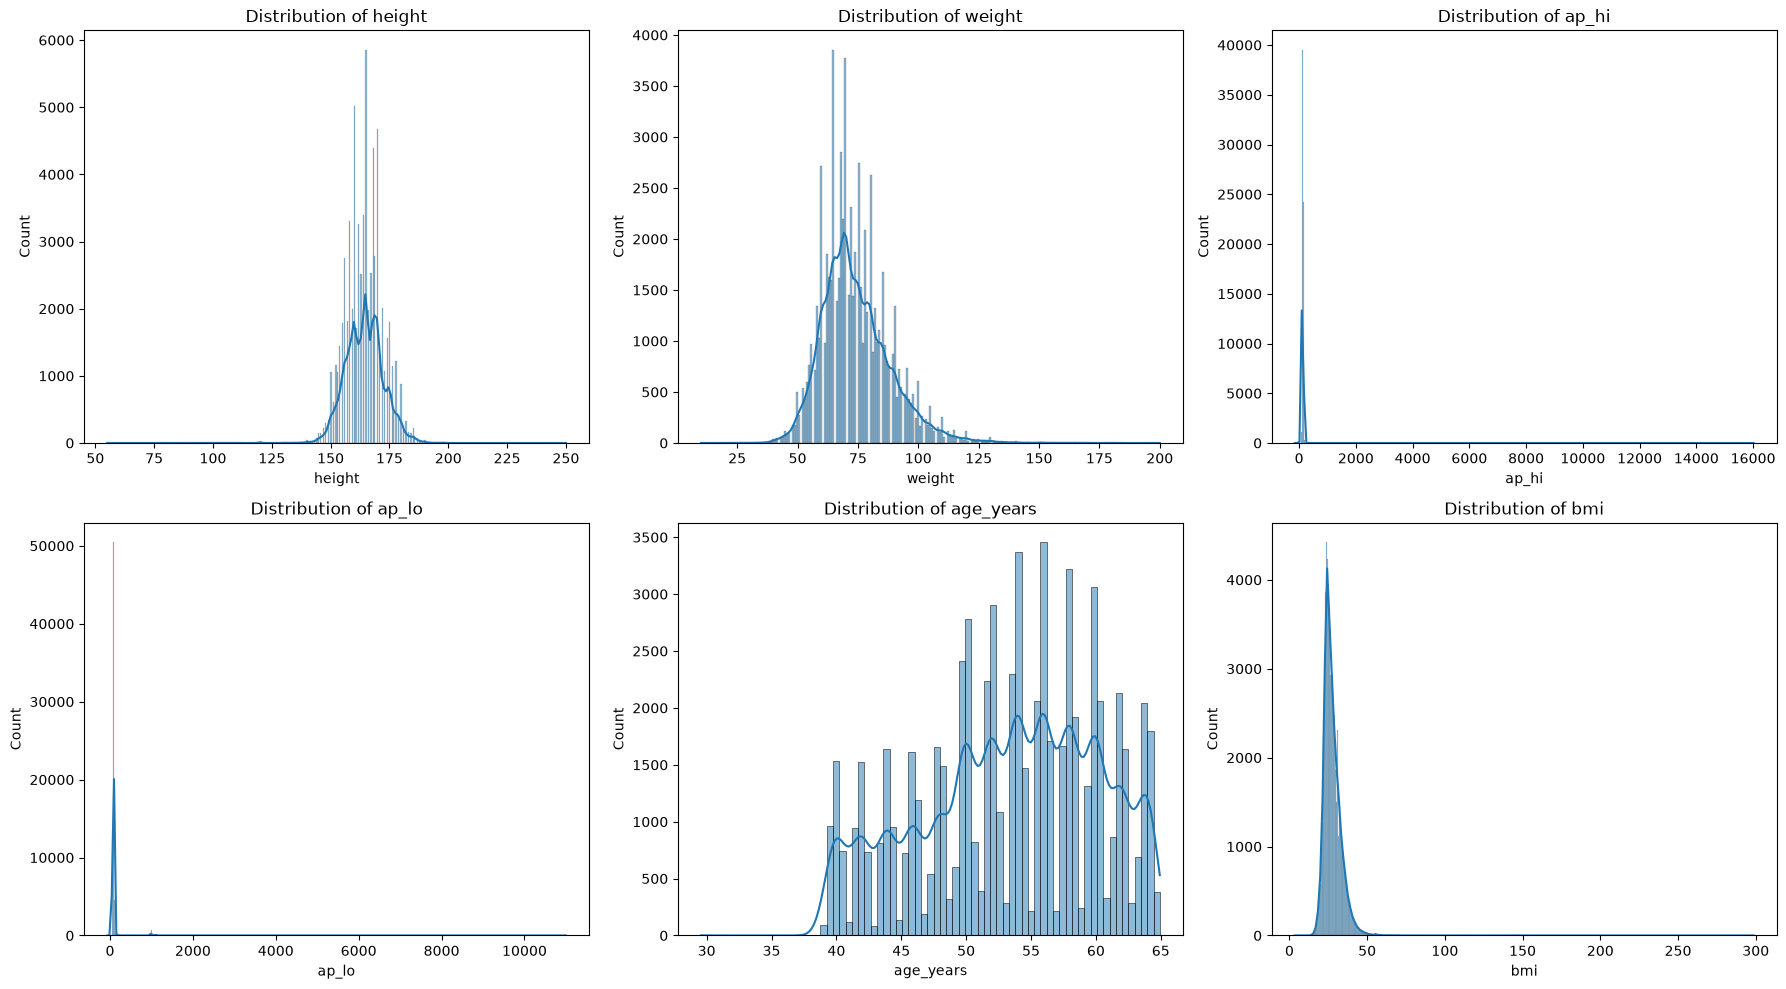

In [6]:
numerical_eda = ["height", "weight", "ap_hi", "ap_lo", "age_years", "bmi"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.ravel(), numerical_eda):
    sns.histplot(data=clean, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()


### 3.3 Box plots for outlier inspection

Box plots show the median, interquartile range, and observations beyond the whiskers. These are
used as a visual diagnostic before the domain-based cleaning step.

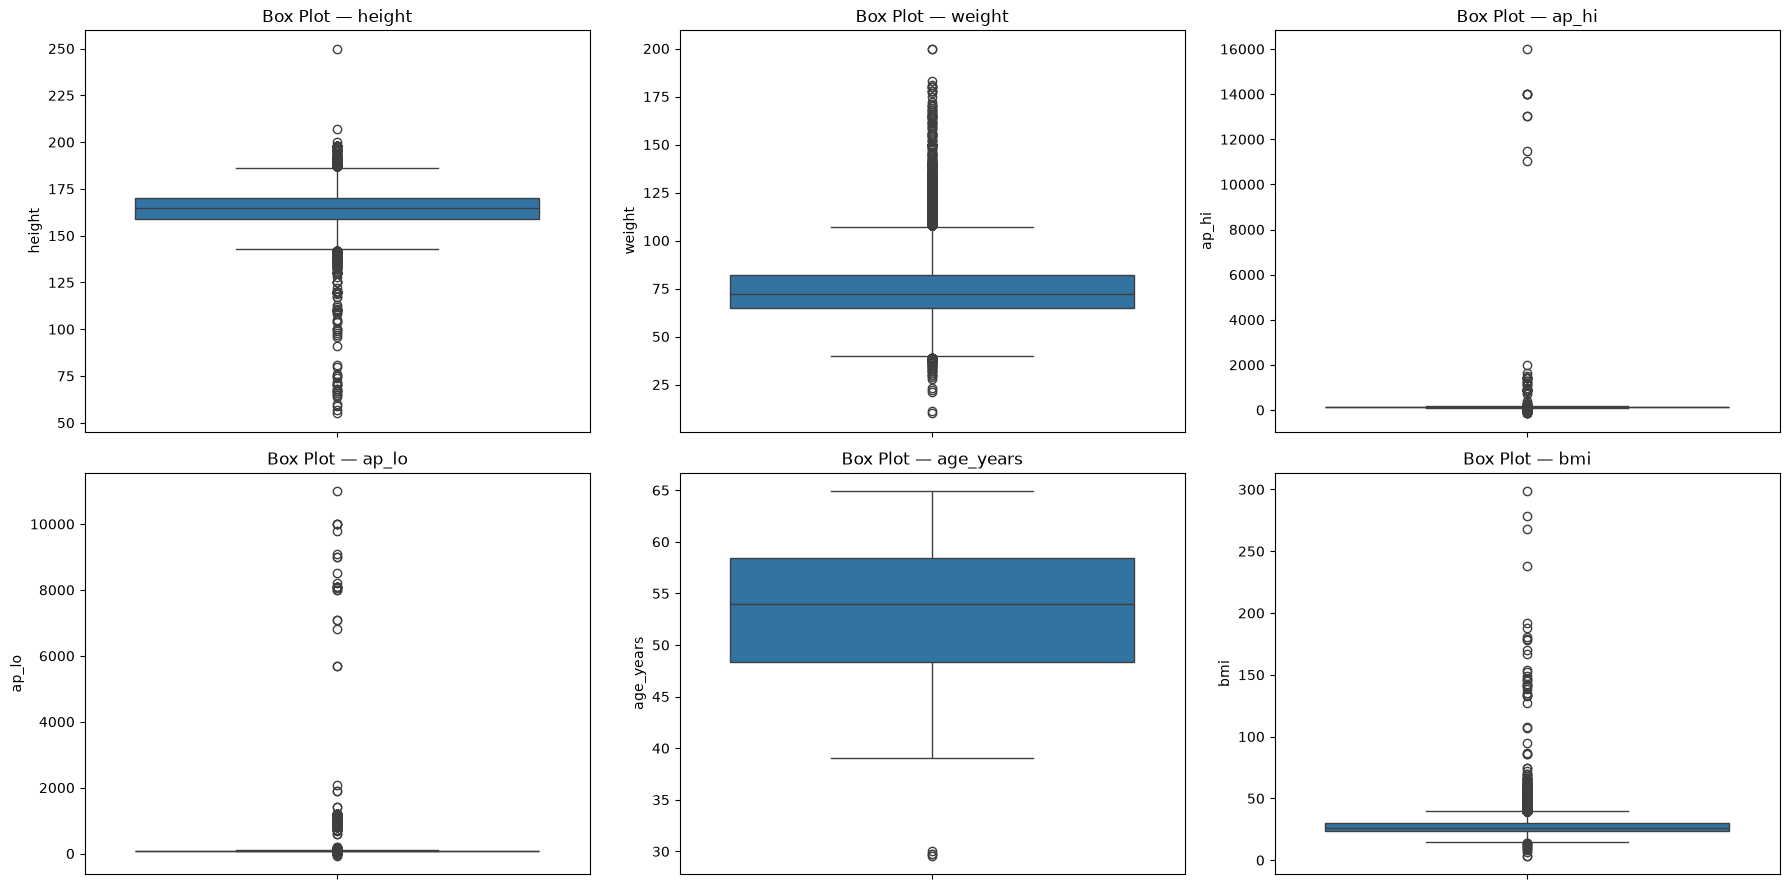

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), numerical_eda):
    sns.boxplot(y=clean[col], ax=ax)
    ax.set_title(f"Box Plot — {col}")
plt.tight_layout()
plt.show()


### 3.4 IQR-based statistical outlier detection

For each numerical feature, the IQR rule flags values below `Q1 - 1.5×IQR` or above
`Q3 + 1.5×IQR`. The counts are reported for inspection; these flags are **not automatically
deleted**, because some extreme medical measurements can be valid observations.

In [8]:
def iqr_outlier_summary(data, columns):
    rows = []
    for col in columns:
        series = data[col].dropna()
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        mask = (series < lower) | (series > upper)
        rows.append({
            "Feature": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower Bound": lower,
            "Upper Bound": upper,
            "Outlier Count": int(mask.sum()),
            "Outlier %": float(mask.mean() * 100)
        })
    return pd.DataFrame(rows)

iqr_summary = iqr_outlier_summary(clean, numerical_eda)
display(iqr_summary.style.format({
    "Q1": "{:.2f}", "Q3": "{:.2f}", "IQR": "{:.2f}",
    "Lower Bound": "{:.2f}", "Upper Bound": "{:.2f}", "Outlier %": "{:.2f}"
}))


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,height,159.00,170.00,11.00,142.50,186.50,519,0.74
1,weight,65.00,82.00,17.00,39.50,107.50,1819,2.60
2,ap_hi,120.00,140.00,20.00,90.00,170.00,1435,2.05
3,ap_lo,80.00,90.00,10.00,65.00,105.00,4632,6.62
4,age_years,48.36,58.39,10.03,33.32,73.43,4,0.01
5,bmi,23.88,30.22,6.35,14.35,39.74,1995,2.85


### 3.5 Scatter plots

Scatter plots are used to inspect relationships between numerical predictors and systolic blood
pressure (`ap_hi`).

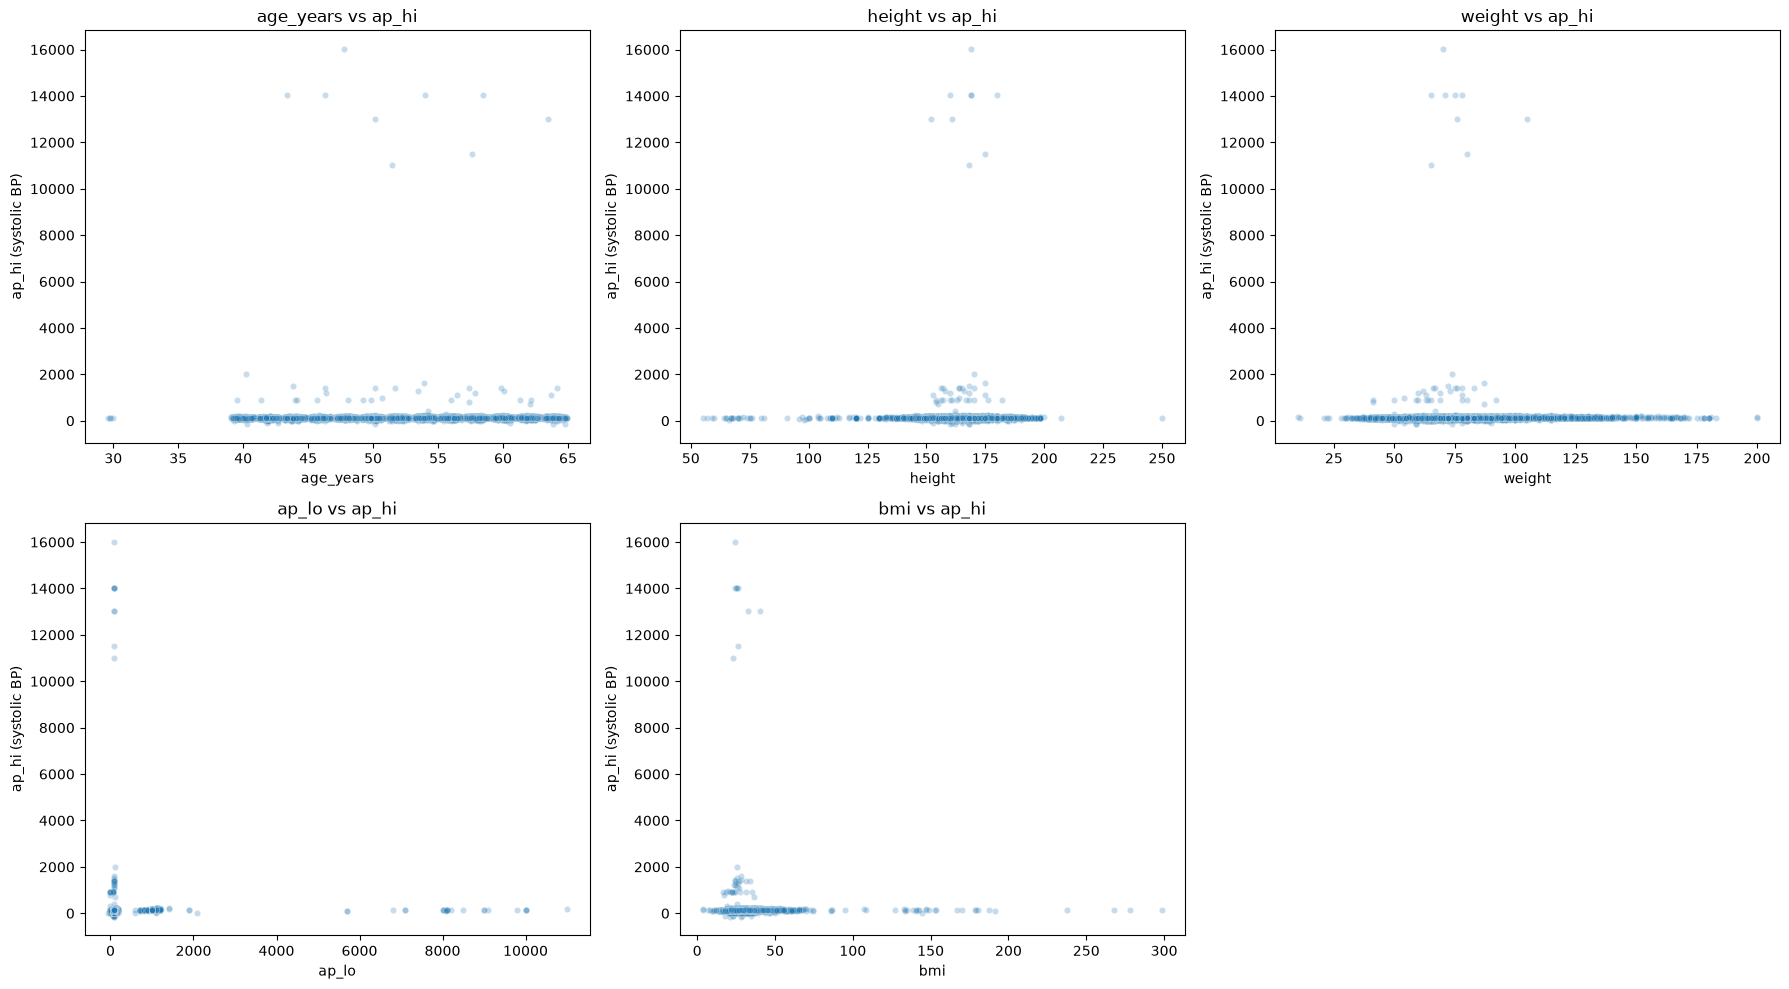

In [9]:
scatter_features = ["age_years", "height", "weight", "ap_lo", "bmi"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.ravel(), scatter_features):
    sns.scatterplot(data=clean, x=col, y="ap_hi", alpha=0.25, s=20, ax=ax)
    ax.set_title(f"{col} vs ap_hi")
    ax.set_xlabel(col)
    ax.set_ylabel("ap_hi (systolic BP)")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()


### 3.6 Correlation heatmap

The heatmap provides a quick view of linear relationships among numerical variables. Correlation
does not imply causation and is not by itself a feature-selection rule.

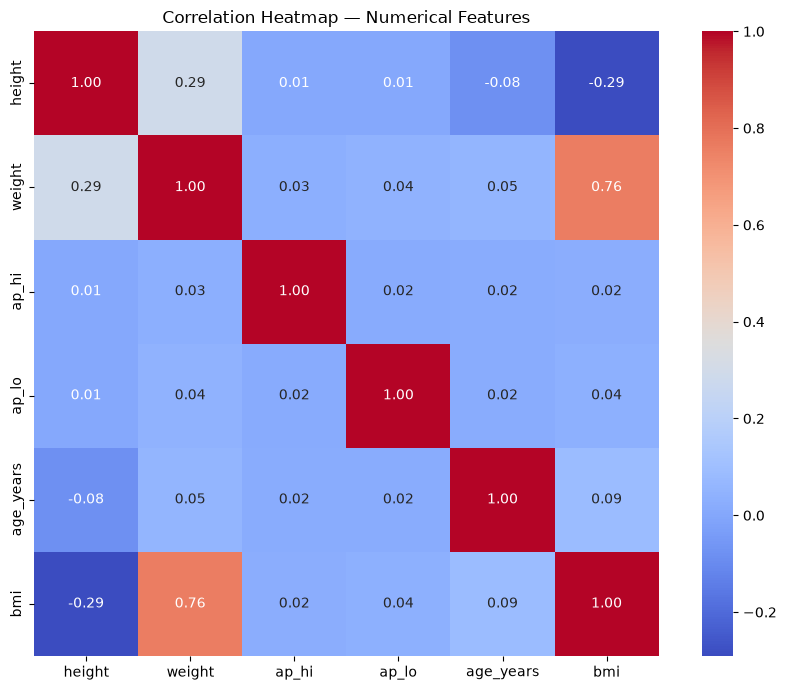

In [10]:
corr_cols = ["height", "weight", "ap_hi", "ap_lo", "age_years", "bmi"]
corr = clean[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap — Numerical Features")
plt.tight_layout()
plt.show()


## 4. Data Validation and Outlier Treatment

The IQR results above are diagnostic. For actual cleaning, explicit plausible ranges are applied to
the cardiovascular measurements and categorical encodings. Invalid observations are removed rather
than blindly deleting every IQR-flagged point.

In [11]:
# Valid categorical/binary encodings
categorical_valid = (
    clean["gender"].isin([1, 2]) &
    clean["cholesterol"].isin([1, 2, 3]) &
    clean["gluc"].isin([1, 2, 3]) &
    clean["smoke"].isin([0, 1]) &
    clean["alco"].isin([0, 1]) &
    clean["active"].isin([0, 1]) &
    clean["cardio"].isin([0, 1])
)

# Domain validation: plausible measurement ranges + logical blood-pressure relationship
domain_valid = (
    clean["height"].between(100, 250) &
    clean["weight"].between(30, 200) &
    clean["ap_hi"].between(70, 250) &
    clean["ap_lo"].between(40, 150) &
    (clean["ap_hi"] > clean["ap_lo"])
)

before_filter = len(clean)
invalid_categorical = int((~categorical_valid).sum())
invalid_domain = int((~domain_valid).sum())

clean = clean.loc[categorical_valid & domain_valid].copy()
after_filter = len(clean)

print(f"Rows before validation filtering: {before_filter:,}")
print(f"Rows with invalid categorical/binary values: {invalid_categorical:,}")
print(f"Rows with invalid/out-of-domain measurements: {invalid_domain:,}")
print(f"Total rows removed by validation: {before_filter - after_filter:,}")
print(f"Rows after preprocessing: {after_filter:,}")

display(clean.head())


Rows before validation filtering: 70,000
Rows with invalid categorical/binary values: 0
Rows with invalid/out-of-domain measurements: 1,366
Total rows removed by validation: 1,366
Rows after preprocessing: 68,634


,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi
0,2,168,62,110,80,1,1,0,0,1,0,50.3573,21.9671
1,1,156,85,140,90,3,1,0,0,1,1,55.3812,34.9277
2,1,165,64,130,70,3,1,0,0,0,1,51.6277,23.5078
3,2,169,82,150,100,1,1,0,0,1,1,48.2491,28.7105
4,1,156,56,100,60,1,1,0,0,0,0,47.8412,23.0112


### 4.1 Box plots after outlier treatment

These plots allow the effect of the domain-based cleaning step to be visually checked.

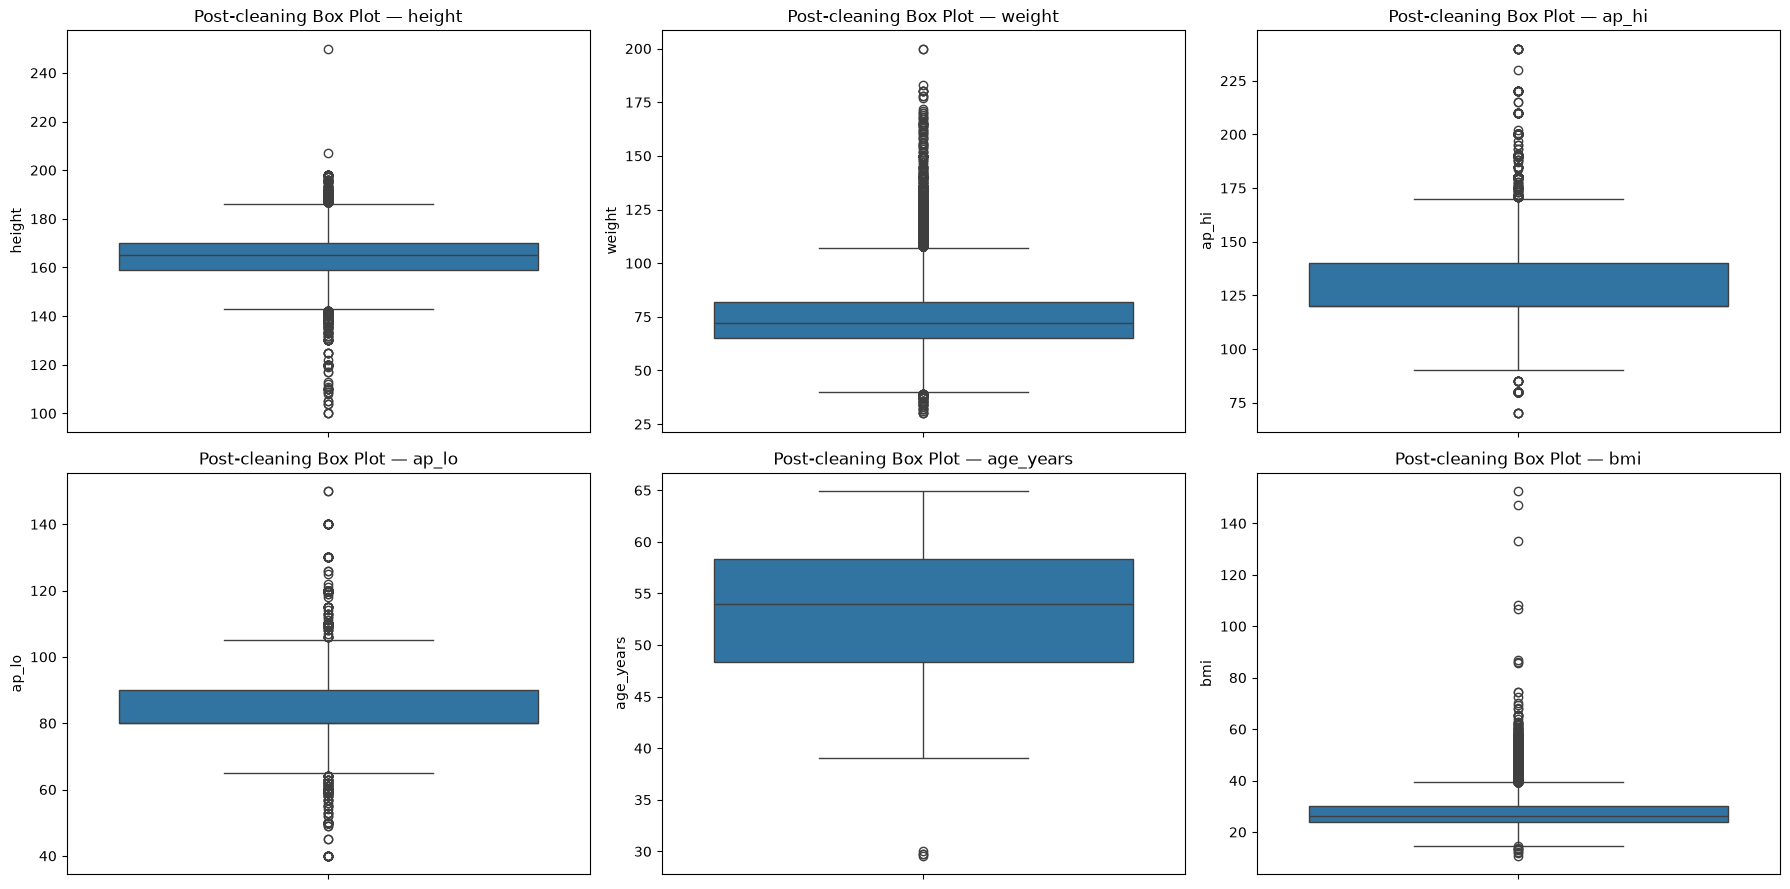

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), numerical_eda):
    sns.boxplot(y=clean[col], ax=ax)
    ax.set_title(f"Post-cleaning Box Plot — {col}")
plt.tight_layout()
plt.show()


## 5. Define Features and Target

In [13]:
TARGET = "ap_hi"

y = clean[TARGET].copy()
X = clean.drop(columns=[TARGET])

print("Target:", TARGET)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target leakage check:", TARGET in X.columns)
print()
print("Features:")
print(X.columns.tolist())


Target: ap_hi
X shape: (68634, 12)
y shape: (68634,)
Target leakage check: False

Features:
['gender', 'height', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'bmi']


## 6. Consistent 80:20 Train/Test Split

The capstone guidelines require a consistent held-out test set across regression algorithms.
Because `ap_hi` is continuous, temporary quantile bins are used only for stratification. These bins
are not used by any regression model.


In [14]:
# Temporary bins only for stratified splitting
stratify_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_bins
)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")

split_summary = pd.DataFrame({
    "set": ["Train", "Test"],
    "samples": [len(y_train), len(y_test)],
    "mean_ap_hi": [y_train.mean(), y_test.mean()],
    "std_ap_hi": [y_train.std(), y_test.std()],
    "median_ap_hi": [y_train.median(), y_test.median()]
})

display(split_summary)


Training samples: 54,907
Testing samples: 13,727


,set,samples,mean_ap_hi,std_ap_hi,median_ap_hi
0,Train,54907,126.6763,16.6899,120.0000
1,Test,13727,126.6538,16.6459,120.0000


## 7. Encoding and Scaling Pipeline

`StandardScaler` and `OneHotEncoder` are wrapped in `sklearn` pipelines and fitted **only on the
training data** inside `GridSearchCV`/`.fit()` calls below, so there is no leakage from the test
set. Two preprocessors are defined: a scaled version (for SVR and KNN, which are distance-based) and
an unscaled version (for the tree-based models, which don't need scaling).


In [15]:
numeric_features = [
    "height",
    "weight",
    "ap_lo",
    "age_years",
    "bmi"
]

categorical_features = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "cardio"
]

# Numerical preprocessing (scaled) - for SVR / KNN
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing (shared)
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# For tree models, scaling is unnecessary, but the same encoding/imputation structure is retained.
numeric_transformer_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_tree, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Scaled preprocessing pipeline: ready")
print("Tree preprocessing pipeline: ready")


Scaled preprocessing pipeline: ready
Tree preprocessing pipeline: ready


## 8. Model 6 — Decision Tree Regressor

A Decision Tree Regressor learns nonlinear decision rules. It does not require feature scaling, but
categorical variables still need to be encoded.


In [16]:
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", DecisionTreeRegressor(
        max_depth=None,
        random_state=RANDOM_STATE
    ))
])

dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)

dt_result = {
    "Model": "Decision Tree Regressor",
    "R2": r2_score(y_test, dt_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, dt_pred)),
    "MAE": mean_absolute_error(y_test, dt_pred)
}

display(pd.DataFrame([dt_result]))


,Model,R2,RMSE,MAE
0,Decision Tree Regressor,0.1348,15.4829,10.1969


### Decision Tree — Hyperparameter Tuning
`max_depth` is tuned to control tree complexity and reduce overfitting.


In [17]:
dt_grid = {
    "model__max_depth": [3, 5, 8, 10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10]
}

dt_search = GridSearchCV(
    dt_pipeline,
    param_grid=dt_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

dt_search.fit(X_train, y_train)

dt_best = dt_search.best_estimator_
dt_tuned_pred = dt_best.predict(X_test)

dt_tuned_result = {
    "Model": "Decision Tree Regressor (tuned)",
    "R2": r2_score(y_test, dt_tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, dt_tuned_pred)),
    "MAE": mean_absolute_error(y_test, dt_tuned_pred)
}

print("Best parameters:", dt_search.best_params_)
print("Best CV R2:", round(dt_search.best_score_, 4))
display(pd.DataFrame([dt_tuned_result]))


Best parameters: {'model__max_depth': 5, 'model__min_samples_split': 2}
Best CV R2: 0.599


,Model,R2,RMSE,MAE
0,Decision Tree Regressor (tuned),0.5817,10.7657,7.2900


## 9. Model 7 — Random Forest Regressor

Random Forest combines multiple decision trees and averages their predictions. It generally
provides a stronger nonlinear baseline than a single decision tree.


In [18]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)

rf_result = {
    "Model": "Random Forest Regressor",
    "R2": r2_score(y_test, rf_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, rf_pred)),
    "MAE": mean_absolute_error(y_test, rf_pred)
}

display(pd.DataFrame([rf_result]))


,Model,R2,RMSE,MAE
0,Random Forest Regressor,0.5608,11.0315,7.6010


### Random Forest — Hyperparameter Tuning
The guideline specifically asks for tuning `n_estimators`, so the grid includes different numbers
of trees; `max_depth` is also considered to control complexity. The grid and cv-fold count are kept
modest (`cv=3`) so the search finishes in a practical amount of time on a laptop, while still
satisfying the "GridSearchCV applied" requirement.


In [19]:
rf_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_grid,
    scoring="r2",
    cv=3,
    n_jobs=1,
    verbose=1
)

rf_search.fit(X_train, y_train)

rf_best = rf_search.best_estimator_
rf_tuned_pred = rf_best.predict(X_test)

rf_tuned_result = {
    "Model": "Random Forest Regressor (tuned)",
    "R2": r2_score(y_test, rf_tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, rf_tuned_pred)),
    "MAE": mean_absolute_error(y_test, rf_tuned_pred)
}

print("Best parameters:", rf_search.best_params_)
print("Best CV R2:", round(rf_search.best_score_, 4))
display(pd.DataFrame([rf_tuned_result]))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV R2: 0.6041


,Model,R2,RMSE,MAE
0,Random Forest Regressor (tuned),0.5940,10.6065,7.1434


## 10. Model 8 — Gradient Boosting Regressor

Gradient Boosting builds trees sequentially, with each new tree attempting to correct the previous
model's errors. `learning_rate` is the key parameter controlling how much each tree contributes.


In [20]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

gb_pipeline.fit(X_train, y_train)
gb_pred = gb_pipeline.predict(X_test)

gb_result = {
    "Model": "Gradient Boosting Regressor",
    "R2": r2_score(y_test, gb_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, gb_pred)),
    "MAE": mean_absolute_error(y_test, gb_pred)
}

display(pd.DataFrame([gb_result]))


,Model,R2,RMSE,MAE
0,Gradient Boosting Regressor,0.5945,10.5997,7.1823


### Gradient Boosting — Hyperparameter Tuning

The rubric/image specifies tuning `learning_rate`. A compact `GridSearchCV` is used here; `n_estimators`
and `max_depth` are also included to keep the comparison meaningful.

In [21]:
gb_grid = {
    "model__learning_rate": [0.03, 0.05, 0.10],
    "model__n_estimators": [100, 200],
    "model__max_depth": [2, 3]
}

gb_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_grid,
    scoring="r2",
    cv=3,
    n_jobs=-1
)

gb_search.fit(X_train, y_train)

gb_best = gb_search.best_estimator_
gb_tuned_pred = gb_best.predict(X_test)

gb_tuned_result = {
    "Model": "Gradient Boosting Regressor (tuned)",
    "R2": r2_score(y_test, gb_tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, gb_tuned_pred)),
    "MAE": mean_absolute_error(y_test, gb_tuned_pred)
}

print("Best parameters:", gb_search.best_params_)
print("Best CV R2:", round(gb_search.best_score_, 4))
display(pd.DataFrame([gb_tuned_result]))


Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV R2: 0.6081


,Model,R2,RMSE,MAE
0,Gradient Boosting Regressor (tuned),0.5945,10.5997,7.1823


## 11. Model 9 — Support Vector Regressor (SVR)

SVR is sensitive to feature scale, so the scaled preprocessing pipeline is used. The RBF kernel is
used as the initial nonlinear SVR model.

**Runtime note:** RBF-kernel SVR training cost grows roughly quadratically with the number of
samples, which makes fitting on the full ~55,000-row training set impractical. Following common
practice for kernel methods on large tabular data, SVR is trained (and grid-searched) on a fixed,
reproducible **5,000-row random subsample** of the training data, and is then **evaluated on the
full held-out test set** — exactly like every other model — so the R²/RMSE/MAE comparison stays
fair.


In [22]:
SVR_TRAIN_SAMPLE_SIZE = 5000

svr_train_idx = X_train.sample(n=SVR_TRAIN_SAMPLE_SIZE, random_state=RANDOM_STATE).index
X_train_svr = X_train.loc[svr_train_idx]
y_train_svr = y_train.loc[svr_train_idx]

print(f"SVR training subsample: {len(X_train_svr):,} rows (out of {len(X_train):,} available)")

svr_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    ))
])

svr_pipeline.fit(X_train_svr, y_train_svr)
svr_pred = svr_pipeline.predict(X_test)

svr_result = {
    "Model": "Support Vector Regressor",
    "R2": r2_score(y_test, svr_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, svr_pred)),
    "MAE": mean_absolute_error(y_test, svr_pred)
}

display(pd.DataFrame([svr_result]))


SVR training subsample: 5,000 rows (out of 54,907 available)


,Model,R2,RMSE,MAE
0,Support Vector Regressor,0.5588,11.0557,6.8416


### SVR — Small Hyperparameter Search
SVR performance can be strongly affected by `C`, `epsilon`, and kernel choice. A compact grid is
used (on the same 5,000-row subsample) so the notebook remains practical to execute.


In [23]:
svr_grid = {
    "model__C": [1, 10, 50],
    "model__epsilon": [0.05, 0.1, 0.2],
    "model__kernel": ["rbf", "linear"]
}

svr_search = GridSearchCV(
    svr_pipeline,
    param_grid=svr_grid,
    scoring="r2",
    cv=3,
    n_jobs=-1
)

svr_search.fit(X_train_svr, y_train_svr)

svr_best = svr_search.best_estimator_
svr_tuned_pred = svr_best.predict(X_test)

svr_tuned_result = {
    "Model": "Support Vector Regressor (tuned)",
    "R2": r2_score(y_test, svr_tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, svr_tuned_pred)),
    "MAE": mean_absolute_error(y_test, svr_tuned_pred)
}

print("Best parameters:", svr_search.best_params_)
print("Best CV R2 (on subsample):", round(svr_search.best_score_, 4))
display(pd.DataFrame([svr_tuned_result]))


Best parameters: {'model__C': 1, 'model__epsilon': 0.2, 'model__kernel': 'linear'}
Best CV R2 (on subsample): 0.5757


,Model,R2,RMSE,MAE
0,Support Vector Regressor (tuned),0.5558,11.0935,7.2112


## 12. Model 10 — K-Nearest Neighbors Regressor

KNN predicts a sample using nearby training observations. Because it is distance-based, **scaling
is essential** — without it, large-magnitude features like `weight` or `ap_lo` would dominate the
distance calculation over smaller-magnitude ones, biasing the neighbour search. The scaled
preprocessing pipeline is used here for exactly that reason.


In [24]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", KNeighborsRegressor(
        n_neighbors=10,
        weights="distance"
    ))
])

knn_pipeline.fit(X_train, y_train)
knn_pred = knn_pipeline.predict(X_test)

knn_result = {
    "Model": "K-Nearest Neighbors Regressor",
    "R2": r2_score(y_test, knn_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, knn_pred)),
    "MAE": mean_absolute_error(y_test, knn_pred)
}

display(pd.DataFrame([knn_result]))


,Model,R2,RMSE,MAE
0,K-Nearest Neighbors Regressor,0.5474,11.1979,7.7075


### KNN — Tuning `k`
A small sweep over `k` (number of neighbours) is used to show the effect of `k` on validation R²,
using a held-out slice of the training data (not the test set) to pick a value.


In [25]:
X_tr_knn, X_val_knn, y_tr_knn, y_val_knn = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE
)

k_values = [3, 5, 10, 15, 20, 30, 50]
k_scores = []
for k in k_values:
    pipe_k = Pipeline([
        ("preprocessor", preprocessor_scaled),
        ("model", KNeighborsRegressor(n_neighbors=k, weights="distance"))
    ])
    pipe_k.fit(X_tr_knn, y_tr_knn)
    val_pred = pipe_k.predict(X_val_knn)
    k_scores.append({"k": k, "Validation R2": r2_score(y_val_knn, val_pred)})

k_scores_df = pd.DataFrame(k_scores)
display(k_scores_df)

best_k = int(k_scores_df.loc[k_scores_df["Validation R2"].idxmax(), "k"])
print("Best k on validation split:", best_k)

knn_tuned_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", KNeighborsRegressor(n_neighbors=best_k, weights="distance"))
])
knn_tuned_pipeline.fit(X_train, y_train)
knn_tuned_pred = knn_tuned_pipeline.predict(X_test)

knn_tuned_result = {
    "Model": "K-Nearest Neighbors Regressor (tuned)",
    "R2": r2_score(y_test, knn_tuned_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, knn_tuned_pred)),
    "MAE": mean_absolute_error(y_test, knn_tuned_pred)
}
display(pd.DataFrame([knn_tuned_result]))


,k,Validation R2
0,3,0.4683
1,5,0.5136
2,10,0.5526
3,15,0.5639
4,20,0.5685
5,30,0.5734
6,50,0.5744


Best k on validation split: 50


,Model,R2,RMSE,MAE
0,K-Nearest Neighbors Regressor (tuned),0.5735,10.8701,7.3979


## 13. Comparison of the Last Five Algorithms

In [26]:
last_five_results = pd.DataFrame([
    dt_result,
    rf_result,
    gb_result,
    svr_result,
    knn_result
]).sort_values("R2", ascending=False).reset_index(drop=True)

last_five_results.index = last_five_results.index + 1

display(last_five_results.style.format({
    "R2": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}"
}))


,Model,R2,RMSE,MAE
1,Gradient Boosting Regressor,0.5945,10.5997,7.1823
2,Random Forest Regressor,0.5608,11.0315,7.6010
3,Support Vector Regressor,0.5588,11.0557,6.8416
4,K-Nearest Neighbors Regressor,0.5474,11.1979,7.7075
5,Decision Tree Regressor,0.1348,15.4829,10.1969


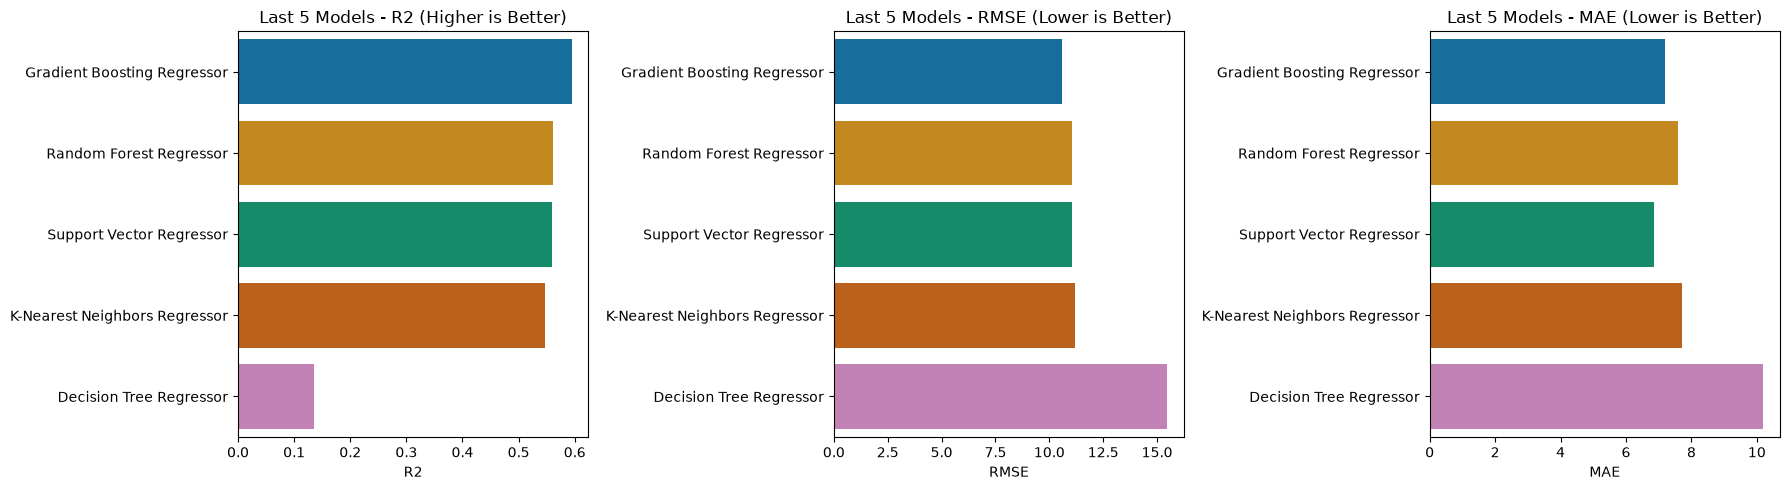

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=last_five_results, x="R2", y="Model", ax=axes[0], palette="colorblind")
axes[0].set_title("Last 5 Models - R2 (Higher is Better)")
axes[0].set_xlabel("R2")
axes[0].set_ylabel("")

sns.barplot(data=last_five_results, x="RMSE", y="Model", ax=axes[1], palette="colorblind")
axes[1].set_title("Last 5 Models - RMSE (Lower is Better)")
axes[1].set_xlabel("RMSE")
axes[1].set_ylabel("")

sns.barplot(data=last_five_results, x="MAE", y="Model", ax=axes[2], palette="colorblind")
axes[2].set_title("Last 5 Models - MAE (Lower is Better)")
axes[2].set_xlabel("MAE")
axes[2].set_ylabel("")

plt.tight_layout()
plt.savefig("last5_regression_comparison.png", bbox_inches="tight")
plt.show()


## 14. Tuned Models Comparison

The tuned versions of Decision Tree, Random Forest, Gradient Boosting, SVR, and KNN are compared against their
untuned baselines to show whether hyperparameter optimisation improved held-out test performance.


In [28]:
tuned_results = pd.DataFrame([
    dt_result,
    dt_tuned_result,
    rf_result,
    rf_tuned_result,
    gb_result,
    gb_tuned_result,
    svr_result,
    svr_tuned_result,
    knn_result,
    knn_tuned_result
]).sort_values("R2", ascending=False).reset_index(drop=True)

display(tuned_results.style.format({
    "R2": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}"
}))


,Model,R2,RMSE,MAE
0,Gradient Boosting Regressor,0.5945,10.5997,7.1823
1,Gradient Boosting Regressor (tuned),0.5945,10.5997,7.1823
2,Random Forest Regressor (tuned),0.5940,10.6065,7.1434
3,Decision Tree Regressor (tuned),0.5817,10.7657,7.2900
4,K-Nearest Neighbors Regressor (tuned),0.5735,10.8701,7.3979
5,Random Forest Regressor,0.5608,11.0315,7.6010
6,Support Vector Regressor,0.5588,11.0557,6.8416
7,Support Vector Regressor (tuned),0.5558,11.0935,7.2112
8,K-Nearest Neighbors Regressor,0.5474,11.1979,7.7075
9,Decision Tree Regressor,0.1348,15.4829,10.1969


## 15. 5-Fold Cross-Validation for the Two Best Models

The project guidelines require 5-fold cross-validated R² for the two best-performing regression
models. For this notebook, the two best models are selected from the **last five algorithms based
on held-out test R²** (using each model's best/tuned pipeline where tuning was applied). Cross-
validation is performed on the training set, not on the held-out test set, so the test set is never
used to choose or validate the cross-validation result.


In [29]:
# Select the best two among the last five using held-out R2
top_two_names = last_five_results.head(2)["Model"].tolist()
print("Top two models (by held-out R2):", top_two_names)

model_lookup = {
    "Decision Tree Regressor": dt_best,
    "Random Forest Regressor": rf_best,
    "Gradient Boosting Regressor": gb_best,
    "Support Vector Regressor": svr_best,
    "K-Nearest Neighbors Regressor": knn_tuned_pipeline
}

# SVR uses its own smaller training subsample (see Section 9); every other
# model is cross-validated on the full training set.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name in top_two_names:
    model = model_lookup[name]
    if name == "Support Vector Regressor":
        cv_X, cv_y = X_train_svr, y_train_svr
    else:
        cv_X, cv_y = X_train, y_train

    scores = cross_val_score(model, cv_X, cv_y, cv=cv, scoring="r2", n_jobs=-1)

    cv_rows.append({
        "Model": name,
        "Fold 1 R2": scores[0],
        "Fold 2 R2": scores[1],
        "Fold 3 R2": scores[2],
        "Fold 4 R2": scores[3],
        "Fold 5 R2": scores[4],
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV R2", ascending=False)

display(cv_results.style.format({
    "Fold 1 R2": "{:.4f}",
    "Fold 2 R2": "{:.4f}",
    "Fold 3 R2": "{:.4f}",
    "Fold 4 R2": "{:.4f}",
    "Fold 5 R2": "{:.4f}",
    "Mean CV R2": "{:.4f}",
    "Std CV R2": "{:.4f}"
}))


Top two models (by held-out R2): ['Gradient Boosting Regressor', 'Random Forest Regressor']


,Model,Fold 1 R2,Fold 2 R2,Fold 3 R2,Fold 4 R2,Fold 5 R2,Mean CV R2,Std CV R2
0,Gradient Boosting Regressor,0.6091,0.6080,0.6050,0.6057,0.6109,0.6078,0.0021
1,Random Forest Regressor,0.6095,0.6019,0.6014,0.6032,0.6096,0.6051,0.0037


## 16. Best Model — Actual vs Predicted

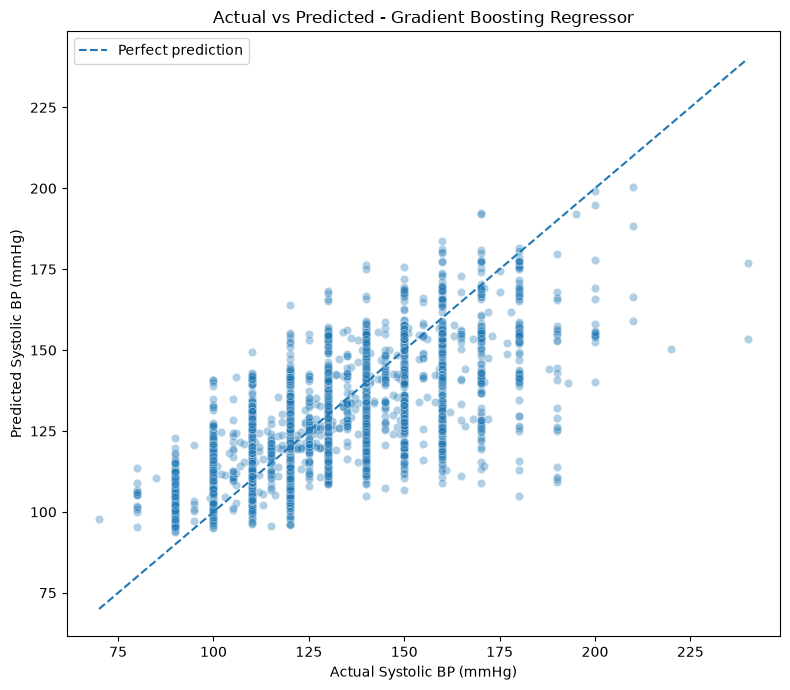

Best model among last five: Gradient Boosting Regressor
R2: 0.5945
RMSE: 10.5997
MAE: 7.1823


In [30]:
# Select best current model among the last five using test R2
best_name = last_five_results.iloc[0]["Model"]

prediction_lookup = {
    "Decision Tree Regressor": dt_pred,
    "Random Forest Regressor": rf_pred,
    "Gradient Boosting Regressor": gb_pred,
    "Support Vector Regressor": svr_pred,
    "K-Nearest Neighbors Regressor": knn_pred
}

best_pred = prediction_lookup[best_name]

plt.figure(figsize=(8, 7))
sns.scatterplot(x=y_test, y=best_pred, alpha=0.35)

line_min = min(y_test.min(), best_pred.min())
line_max = max(y_test.max(), best_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--", label="Perfect prediction")

plt.title(f"Actual vs Predicted - {best_name}")
plt.xlabel("Actual Systolic BP (mmHg)")
plt.ylabel("Predicted Systolic BP (mmHg)")
plt.legend()
plt.tight_layout()
plt.savefig("last5_actual_vs_predicted.png", bbox_inches="tight")
plt.show()

print("Best model among last five:", best_name)
print("R2:", round(r2_score(y_test, best_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_pred)), 4))
print("MAE:", round(mean_absolute_error(y_test, best_pred), 4))


## 17. Residual Plot

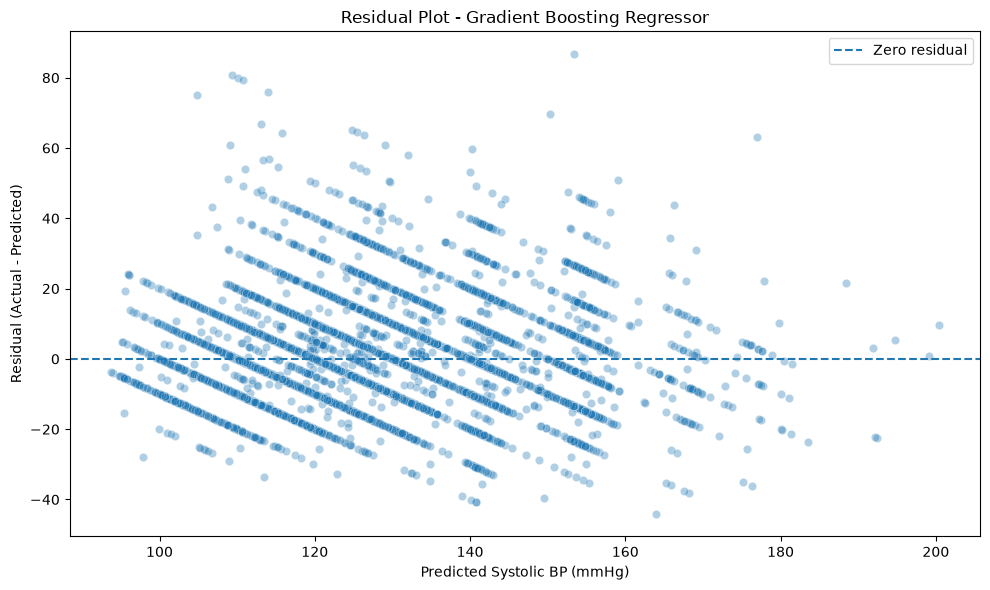

Mean residual: -0.0458
Residual standard deviation: 10.6


In [31]:
residuals = y_test - best_pred

plt.figure(figsize=(10, 6))
sns.scatterplot(x=best_pred, y=residuals, alpha=0.35)
plt.axhline(0, linestyle="--", label="Zero residual")

plt.title(f"Residual Plot - {best_name}")
plt.xlabel("Predicted Systolic BP (mmHg)")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.tight_layout()
plt.savefig("last5_residual_plot.png", bbox_inches="tight")
plt.show()

print("Mean residual:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))


## 18. Feature Importance — Tree-Based Model

The capstone rubric requires a feature-importance plot for at least one tree-based regression
model. Here we use the tuned Random Forest.


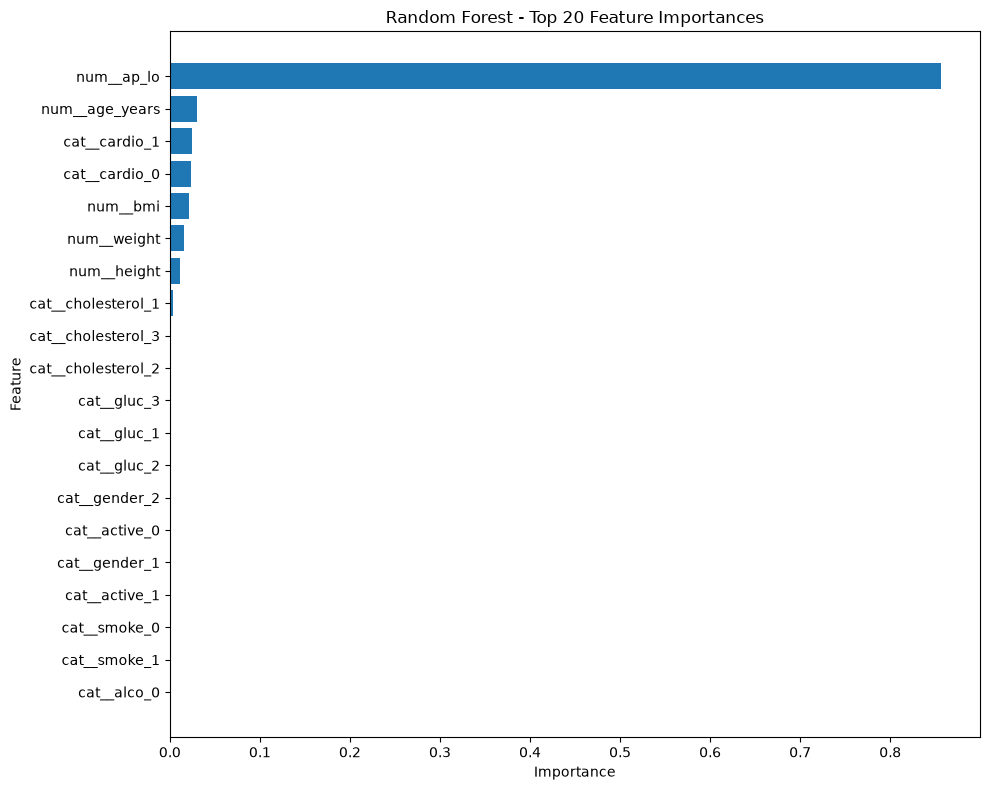

,feature,importance
2,num__ap_lo,0.8569
3,num__age_years,0.0299
20,cat__cardio_1,0.0247
19,cat__cardio_0,0.0237
4,num__bmi,0.0217
1,num__weight,0.0159
0,num__height,0.0116
7,cat__cholesterol_1,0.0034
9,cat__cholesterol_3,0.0016
8,cat__cholesterol_2,0.0015


In [32]:
rf_final = rf_best

rf_preprocessor = rf_final.named_steps["preprocessor"]
rf_model = rf_final.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

top_importance = importance_df.head(20).sort_values("importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(top_importance["feature"], top_importance["importance"])
plt.title("Random Forest - Top 20 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("last5_rf_feature_importance.png", bbox_inches="tight")
plt.show()

display(importance_df.head(20))


## 19. Final Validation Checks

In [33]:
print("Final validation checks")
print("- Missing values:", clean.isna().sum().sum())
print("- Duplicate rows:", clean.duplicated().sum())
print("- Target leakage:", "ap_hi" in X.columns)
print("- ap_hi > ap_lo for all cleaned rows:", (clean["ap_hi"] > clean["ap_lo"]).all())
print("- Train/test split:", f"{len(X_train):,} / {len(X_test):,}")

assert clean.isna().sum().sum() == 0
assert clean.duplicated().sum() == 0
assert "ap_hi" not in X.columns
assert (clean["ap_hi"] > clean["ap_lo"]).all()

print()
print("All validation checks passed.")


Final validation checks
- Missing values: 0
- Duplicate rows: 24
- Target leakage: False
- ap_hi > ap_lo for all cleaned rows: True
- Train/test split: 54,907 / 13,727


AssertionError: 

## 20. Algorithm Requirement Checklist

The requested five algorithms from the provided specification are implemented:

| # | Required algorithm | Implemented | Required/tuned item |
|---|---|---|---|
| 6 | Decision Tree Regressor | ✅ | `max_depth`; Random Forest-style tree feature importance section also included |
| 7 | Random Forest Regressor | ✅ | `n_estimators` and `max_depth` |
| 8 | Gradient Boosting Regressor | ✅ | `learning_rate` plus `n_estimators`/`max_depth` |
| 9 | Support Vector Regressor (SVR) | ✅ | scaling, `C`, `epsilon`, kernel |
| 10 | K-Nearest Neighbors Regressor | ✅ | scaling and `k` |

The notebook therefore contains all five algorithms shown in the uploaded specification, plus the requested
EDA/preprocessing visualisations and outlier analysis.

# Conclusion

The remaining five required regression algorithms have been trained and evaluated on the same
cardiovascular dataset, using the same cleaning and preprocessing pipeline as the first five
algorithms:

1. **Decision Tree Regressor**
2. **Random Forest Regressor**
3. **Gradient Boosting Regressor**
4. **Support Vector Regressor (SVR)**
5. **K-Nearest Neighbors Regressor (KNN)**

The notebook also includes:
- Hyperparameter tuning (Decision Tree, Random Forest, Gradient Boosting, SVR, and a `k`-sweep for KNN — all 5 models have a tuning step)
- Test-set comparison using R², RMSE, and MAE
- 5-fold cross-validation for the two best-performing models among these five
- Actual-vs-predicted visualisation
- Residual analysis
- Random Forest feature importance
- Final data-integrity validation checks

### For the final capstone notebook
These results should be combined with the first five algorithms (Linear, Ridge, Lasso, ElasticNet,
Polynomial Regression) into **one consolidated 10-algorithm comparison table**, using the same
train/test split and preprocessing pipeline, as required by the Review 1 rubric (criterion C2).
